<a href="https://colab.research.google.com/github/NoelAR1103/RNA-Sequence-Differential-Gene-Expression/blob/main/RNA_sequence.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
%pip install -q pydeseq2 pandas numpy matplotlib seaborn

import pandas as pd
from pydeseq2.utils import load_example_data

# 1. Load PyDESeq2's built-in synthetic example (no URLs needed)
counts_df = load_example_data(modality="raw_counts", dataset="synthetic", debug=False)
metadata_df = load_example_data(modality="metadata", dataset="synthetic", debug=False)

# 2. Sanity checks: orientation (samples x genes), alignment, integer counts
assert counts_df.index.equals(metadata_df.index), "Sample IDs don't match"
assert (counts_df.values >= 0).all(), "Negative counts found"
assert (counts_df.dtypes.apply(lambda d: d.kind) == "i").all(), "Counts must be integers"

n_samples, n_genes = counts_df.shape
print(f"Count matrix: {n_samples} samples x {n_genes} genes")
print("\n--- Experimental design ---")
print(metadata_df.value_counts().rename("n_samples"))

print("\n--- First 5 samples, first 6 genes ---")
print(counts_df.iloc[:5, :6])

# 3. Filter low-count genes (standard before DESeq2)
keep = counts_df.columns[counts_df.sum(axis=0) >= 10]
counts_df = counts_df[keep]
print(f"\nKept {len(keep)}/{n_genes} genes after filtering")

Count matrix: 100 samples x 10 genes

--- Experimental design ---
condition  group
A          X        25
           Y        25
B          X        25
           Y        25
Name: n_samples, dtype: int64

--- First 5 samples, first 6 genes ---
         gene1  gene2  gene3  gene4  gene5  gene6
sample1     12     21      4    130     18      0
sample2      1     44      2     63     11     10
sample3      4      4     11    180     21      3
sample4      1     10      2    100     44      9
sample5      1     11      6    135     16      2

Kept 10/10 genes after filtering


In [3]:
import numpy as np
import pandas as pd
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats

# --- Parameters (edit here) ---
DESIGN_COL = "condition"
REF_LEVEL, TEST_LEVEL = "A", "B"
ALPHA = 0.05
LFC_CUTOFF = 1.0            # |log2FC| threshold for calling up/down
OUT_CSV = "deseq2_differential_expression_results.csv"

# 1. Validate the design and set the reference level explicitly
assert DESIGN_COL in metadata_df.columns, f"'{DESIGN_COL}' not in {list(metadata_df.columns)}"
assert set(metadata_df[DESIGN_COL].unique()) == {REF_LEVEL, TEST_LEVEL}, "Unexpected group labels"

metadata_df = metadata_df.copy()
metadata_df[DESIGN_COL] = pd.Categorical(metadata_df[DESIGN_COL], categories=[REF_LEVEL, TEST_LEVEL])
print(f"Testing '{DESIGN_COL}': {TEST_LEVEL} (test) vs {REF_LEVEL} (reference)")

# 2. Fit size factors, dispersions and log fold changes
dds = DeseqDataSet(
    counts=counts_df,
    metadata=metadata_df,
    design=f"~{DESIGN_COL}",
    quiet=True,
)
dds.deseq2()

# 3. Wald test (alpha is also used for independent filtering)
stat_res = DeseqStats(dds, contrast=[DESIGN_COL, TEST_LEVEL, REF_LEVEL], alpha=ALPHA, quiet=True)
stat_res.summary()

# 4. Keep ALL genes; genes with NaN padj (outliers / filtered) are labelled, not dropped
results_df = stat_res.results_df.copy()
results_df.index.name = "gene"

sig = results_df["padj"] < ALPHA
results_df["Regulation"] = np.select(
    [sig & (results_df["log2FoldChange"] >= LFC_CUTOFF),
     sig & (results_df["log2FoldChange"] <= -LFC_CUTOFF)],
    ["Upregulated", "Downregulated"],
    default="Not Significant",
)
results_df = results_df.sort_values("padj")  # NaNs go last

print("\n--- DIFFERENTIAL EXPRESSION SUMMARY ---")
print(results_df["Regulation"].value_counts())
print(f"Genes with NaN padj (outlier/low-count filtered): {results_df['padj'].isna().sum()}")

print("\n--- TOP 10 MOST SIGNIFICANT GENES ---")
print(results_df[["baseMean", "log2FoldChange", "pvalue", "padj", "Regulation"]].head(10))

results_df.to_csv(OUT_CSV)

Testing 'condition': B (test) vs A (reference)

--- DIFFERENTIAL EXPRESSION SUMMARY ---
Regulation
Not Significant    10
Name: count, dtype: int64
Genes with NaN padj (outlier/low-count filtered): 0

--- TOP 10 MOST SIGNIFICANT GENES ---
          baseMean  log2FoldChange    pvalue      padj       Regulation
gene                                                                   
gene2    21.281239        0.538552  0.000329  0.001646  Not Significant
gene5    27.142450        0.582065  0.000168  0.001646  Not Significant
gene4   100.517961       -0.412102  0.000513  0.001710  Not Significant
gene1     8.541317        0.632812  0.028604  0.064150  Not Significant
gene3     5.010123       -0.632830  0.032075  0.064150  Not Significant
gene8    40.358344       -0.270656  0.047227  0.078711  Not Significant
gene10   11.589325        0.386011  0.114518  0.143147  Not Significant
gene9    37.166183       -0.212715  0.110391  0.143147  Not Significant
gene7    28.294023        0.134338  0.3702

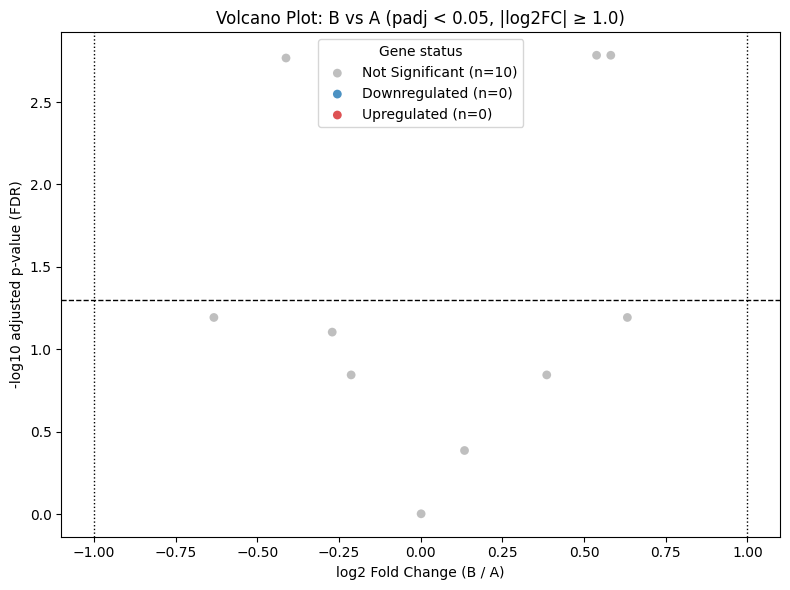

Only 0 significant gene(s) at current thresholds; skipping heatmap.


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

try:
    from adjustText import adjust_text   # optional: pip install adjustText
except ImportError:
    adjust_text = None

# --- Parameters (reuses ALPHA, LFC_CUTOFF, DESIGN_COL, REF_LEVEL, TEST_LEVEL from earlier) ---
N_LABELS = 6          # genes to annotate on the volcano plot
N_HEATMAP = 20        # genes to show in the heatmap
COLORS = {"Upregulated": "#D62728", "Downregulated": "#1F77B4", "Not Significant": "#B0B0B0"}
COND_COLORS = {REF_LEVEL: "#4C72B0", TEST_LEVEL: "#DD8452"}

plot_df = results_df.dropna(subset=["padj"]).copy()
plot_df["neg_log10_padj"] = -np.log10(plot_df["padj"].clip(lower=1e-300))
is_deg = plot_df["Regulation"] != "Not Significant"

# --- 1. VOLCANO PLOT ---
fig, ax = plt.subplots(figsize=(8, 6))

# Draw grey points first so coloured hits sit on top
for label in ["Not Significant", "Downregulated", "Upregulated"]:
    sub = plot_df[plot_df["Regulation"] == label]
    ax.scatter(sub["log2FoldChange"], sub["neg_log10_padj"], c=COLORS[label],
               s=40, alpha=0.8, edgecolor="none", label=f"{label} (n={len(sub)})")

ax.axhline(-np.log10(ALPHA), color="black", linestyle="--", linewidth=1)
ax.axvline(LFC_CUTOFF, color="black", linestyle=":", linewidth=1)
ax.axvline(-LFC_CUTOFF, color="black", linestyle=":", linewidth=1)

# Label the most significant hits (plot_df is already sorted by padj)
texts = [
    ax.text(r["log2FoldChange"], r["neg_log10_padj"], str(gene), fontsize=8.5, fontweight="bold")
    for gene, r in plot_df[is_deg].head(N_LABELS).iterrows()
]
if adjust_text and texts:
    adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle="-", color="grey", lw=0.5))

ax.set(
    title=f"Volcano Plot: {TEST_LEVEL} vs {REF_LEVEL} (padj < {ALPHA}, |log2FC| ≥ {LFC_CUTOFF})",
    xlabel=f"log2 Fold Change ({TEST_LEVEL} / {REF_LEVEL})",
    ylabel="-log10 adjusted p-value (FDR)",
)
ax.legend(title="Gene status", frameon=True)
fig.tight_layout()
fig.savefig("rnaseq_volcano_plot.png", dpi=300)
plt.show()

# --- 2. CLUSTERED HEATMAP (top DEGs) ---
top_genes = plot_df[is_deg].head(N_HEATMAP).index

if len(top_genes) >= 2:
    # Use dds's own sample/gene names so rows and columns always match the fitted model
    norm_counts = pd.DataFrame(dds.layers["normed_counts"],
                               index=dds.obs_names, columns=dds.var_names)
    log_norm = np.log2(norm_counts[top_genes].T + 1)
    log_norm = log_norm[log_norm.std(axis=1) > 0]       # zero-variance rows give NaN z-scores

    col_colors = (metadata_df.loc[log_norm.columns, DESIGN_COL]
                  .astype(str).map(COND_COLORS))

    g = sns.clustermap(
        log_norm,
        z_score=0,                      # standardise each gene (row) across samples
        cmap="RdBu_r",
        col_colors=col_colors,
        xticklabels=log_norm.shape[1] <= 30,   # hide sample labels when there are many
        figsize=(9, 7),
        cbar_kws={"label": "Row z-score (log2 normalised counts)"},
    )
    g.fig.legend(
        handles=[Patch(color=c, label=f"{DESIGN_COL} {k}") for k, c in COND_COLORS.items()],
        loc="upper left", bbox_to_anchor=(0.01, 0.99), frameon=False,
    )
    g.fig.suptitle(f"Top {len(log_norm)} differentially expressed genes", y=1.02, fontweight="bold")
    g.savefig("rnaseq_top_deg_heatmap.png", dpi=300, bbox_inches="tight")
    plt.show()
else:
    print(f"Only {len(top_genes)} significant gene(s) at current thresholds; skipping heatmap.")

In [5]:
import zipfile
from datetime import datetime
from pathlib import Path

import pydeseq2

# --- Parameters (reuses ALPHA, LFC_CUTOFF, DESIGN_COL, REF_LEVEL, TEST_LEVEL, OUT_CSV from earlier) ---
ZIP_NAME = "RNA_Seq_DEG_Portfolio.zip"
REQUIRED = [Path(OUT_CSV), Path("rnaseq_volcano_plot.png")]
OPTIONAL = [Path("rnaseq_top_deg_heatmap.png")]   # skipped upstream if < 2 significant genes

# 1. Fail early if core outputs are missing; tolerate missing optional ones
missing = [p for p in REQUIRED if not p.exists()]
if missing:
    raise FileNotFoundError(f"Run the DESeq2 and plotting cells first. Missing: {[str(p) for p in missing]}")
files_to_zip = REQUIRED + [p for p in OPTIONAL if p.exists()]
skipped = [str(p) for p in OPTIONAL if not p.exists()]

# 2. Short README so the zip is self-explanatory and reproducible
counts = results_df["Regulation"].value_counts()
readme = f"""RNA-Seq differential expression results
Generated: {datetime.now():%Y-%m-%d %H:%M}

Contrast: {DESIGN_COL}: {TEST_LEVEL} (test) vs {REF_LEVEL} (reference)
Thresholds: padj < {ALPHA}, |log2FC| >= {LFC_CUTOFF}
Genes tested: {len(results_df)}
Upregulated: {counts.get('Upregulated', 0)} | Downregulated: {counts.get('Downregulated', 0)} | Not significant: {counts.get('Not Significant', 0)}
Genes with NaN padj: {results_df['padj'].isna().sum()}
PyDESeq2 version: {pydeseq2.__version__}

Files:
""" + "\n".join(f"- {p.name}" for p in files_to_zip)
if skipped:
    readme += "\n\nNot generated (insufficient significant genes): " + ", ".join(skipped)

# 3. Build the zip (arcname keeps the archive flat regardless of working directory)
with zipfile.ZipFile(ZIP_NAME, "w", zipfile.ZIP_DEFLATED) as zf:
    for p in files_to_zip:
        zf.write(p, arcname=p.name)
        print(f"Added: {p.name}")
    zf.writestr("README.txt", readme)
    print("Added: README.txt")

for s in skipped:
    print(f"Note: {s} not found, skipped (optional).")

# 4. Download only when running in Colab; otherwise just report the path
try:
    from google.colab import files
    files.download(ZIP_NAME)
except ImportError:
    print(f"\nNot running in Colab. Archive saved at: {Path(ZIP_NAME).resolve()}")

Added: deseq2_differential_expression_results.csv
Added: rnaseq_volcano_plot.png
Added: README.txt
Note: rnaseq_top_deg_heatmap.png not found, skipped (optional).


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>